# **TP2 - Parte 1: dataset y preprocesamiento**

Notebook de documentación y tratamiento del dataset **70 Dog Breeds Image Dataset**: análisis
exploratorio, control de calidad, conjunto independiente de evaluación, preprocesamiento,
data augmentation y splits (ver `ENUNCIADO.md`, sección 3).

Lo que produce esta notebook lo reutilizan `2-train.ipynb` y `train_classifier`: los splits
finales (CSV/JSON con rutas y etiquetas), el conjunto independiente y el preprocesamiento
encapsulado en un módulo de `src/lib/`.

**Notebook en Google Colab**: https://colab.research.google.com/github/luciajaureguiheisterborg-eng/tuia-dog-recognition-app/blob/feature/tp2-razas-perros/1-pre-processing.ipynb


## Equipo
- Alumno 1 : Jauregui, Lucía
- Alumno 2 : Nebbia, Maria Sofía

## 1. Clonar el repositorio

In [1]:
REPO_URL = "https://github.com/luciajaureguiheisterborg-eng/tuia-dog-recognition-app.git"
!git clone -b feature/tp2-razas-perros $REPO_URL proyecto
%cd proyecto

Cloning into 'proyecto'...
remote: Enumerating objects: 156, done.
remote: Counting objects: 100% (156/156), done.
remote: Compressing objects: 100% (79/79), done.
remote: Total 156 (delta 82), reused 146 (delta 74), pack-reused 0 (from 0)
Receiving objects: 100% (156/156), 5.89 MiB | 5.77 MiB/s, done.
Resolving deltas: 100% (82/82), done.
/content/proyecto


## 2. Instalar dependencias

Colab ya incluye torch, torchvision, opencv, numpy, scikit-learn y matplotlib;
solo se instala lo que falta.

In [2]:
!pip install -q pydantic-settings python-dotenv kagglehub albumentations onnxruntime

import os
import sys
from pathlib import Path
import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from PIL import Image

%pip install -q imagehash
import imagehash

## 3. Configuración del entorno

En Colab no hay PostgreSQL, por lo que se desactiva pgvector y se usa la base vectorial JSON.
La configuración se define por variables de entorno **antes** de importar `lib`.

In [3]:
os.environ["USE_PGVECTOR"] = "false"
# Ajustá acá cualquier otra variable (IMAGE_SIZE, EMBEDDING_DIM, paths, etc.)

ROOT = Path.cwd()
# Si estamos en Colab y se clonó en 'proyecto'
if (ROOT / "proyecto").exists():
    sys.path.insert(0, str(ROOT / "proyecto" / "src"))
else:
    sys.path.insert(0, str(ROOT / "src"))

try:
    from lib.config import settings
    print("dataset_path:", settings.dataset_path)
except ModuleNotFoundError as e:
    print(f"Error de importación: {e}")
    print("Asegúrate de haber clonado correctamente el repositorio en el paso 1 y de que la carpeta 'src' exista.")

import torch
print("GPU disponible:", torch.cuda.is_available())

dataset_path: data/dataset
GPU disponible: True


## 4. Descargar el dataset

In [4]:
!python scripts/download_dataset.py
!ls data/dataset

Descargando gpiosenka/70-dog-breedsimage-data-set ...
100% 215M/215M [00:12<00:00, 18.2MB/s]
Extracting files...
Dataset disponible en /content/proyecto/data/dataset
dogs.csv  test	train  valid


## 5. Descripción del dataset

Usamos el **70 Dog Breeds Image Dataset** (Kaggle, autor gpiosenka): imágenes de perros de **70 razas**, en carpetas por raza y divididas en tres splits.

| Split | Imágenes | Razas | Imágenes por raza (mín – mediana – máx) |
|---|---|---|---|
| train | 7.946 | 70 | 65 – 111,5 – 198 |
| valid | 700 | 70 | 10 – 10 – 10 |
| test | 700 | 70 | 10 – 10 – 10 |
| **Total** | **9.346** | **70** | |

- **Balance:** `valid` y `test` están perfectamente balanceados (10 por raza). `train` está desbalanceado de forma moderada: la raza con más imágenes (Shih-Tzu, 198) tiene unas 3 veces las de la que menos tiene (American Hairless, 65).
- **Formato y resolución:** las 9.346 imágenes son JPEG, en color (RGB), de 224 × 224 píxeles. Ninguna está corrupta.
- **Tamaño de `valid`/`test`:** con solo 10 imágenes por raza, cada acierto o error mueve el resultado por raza 10 puntos, así que las métricas por raza son poco estables. Las métricas globales (sobre 700 imágenes) sí son más confiables.
- **Etiquetas:** el CSV tenía una raza escrita de dos formas (ver sección 7), corregida antes de usar los datos.
- **Licencia:** CC0 1.0 (dominio público), según la página del dataset en Kaggle (consultada el 19/11/2026). Permite el uso que le damos (trabajo académico).

### Encuadre frente a los recortes de YOLO
En las imágenes de muestra, el perro ocupa gran parte del cuadro, está centrado y es el único sujeto, casi siempre de cuerpo entero o en primer plano. Todas las imágenes son cuadradas (224 × 224).
En la Etapa 3, el clasificador va a recibir **recortes de YOLO**, que serán distintos: relaciones de aspecto alargadas, perros parcialmente tapados por otros perros o personas, recortes más chicos reescalados a 224 px (y por lo tanto más borrosos) y fondos distintos. Esa diferencia es un **cambio de dominio** que vamos a medir con el conjunto independiente.

### Limitaciones del dataset
- **Razas muy parecidas**: por ejemplo Labrador y Golden Retriever, o Malinois y Pastor Alemán, difíciles de distinguir incluso para una persona, sobre todo en cachorros.
- **Variación dentro de una raza**: una misma raza aparece en colores y edades muy distintos (p. ej. Labrador negro, amarillo y chocolate).
- **Fuente web**: las imágenes provienen de internet, con posibles errores de etiqueta y duplicados (los revisamos en la sección 7).
- **Cantidad desigual y pequeña** de imágenes por raza (65 a 198 en `train`) y solo 10 en `valid` y `test`: las métricas por raza son poco estables.
- **Sin mestizos, sin imágenes de varios perros ni escenas complejas**: el dataset no representa lo que ve el sistema en uso real.
- **Errores de ortografía en etiquetas**: una raza escrita de dos formas en el CSV (corregida) y "German Sheperd" sin la "h" (se mantiene el nombre original).

In [5]:
root = Path("data/dataset")
df = pd.read_csv(root / "dogs.csv").rename(
    columns={"filepaths": "path", "labels": "breed", "data set": "split"}
)
# Corrige etiqueta con espacios duplicados (ver sección 7)
df["breed"] = df["breed"].str.split().str.join(" ")

print("Archivos del CSV que existen:", df["path"].map(lambda p: (root / p).exists()).all())
print("Razas:", df["breed"].nunique())

conteo = df.groupby(["breed", "split"]).size().unstack("split").fillna(0).astype(int)
print(conteo.describe().loc[["mean", "50%", "min", "max"]])

Archivos del CSV que existen: True
Razas: 70
split  test       train  valid
mean   10.0  113.514286   10.0
50%    10.0  111.500000   10.0
min    10.0   65.000000   10.0
max    10.0  198.000000   10.0


## 6. Análisis exploratorio (EDA)



### Ejemplos visuales
Se muestran imágenes de razas parecidas (Labrador y Golden Retriever, Malinois y Pastor Alemán) para ver por qué se confunden: color de pelaje, tamaño y pose muy similares, sobre todo en cachorros.

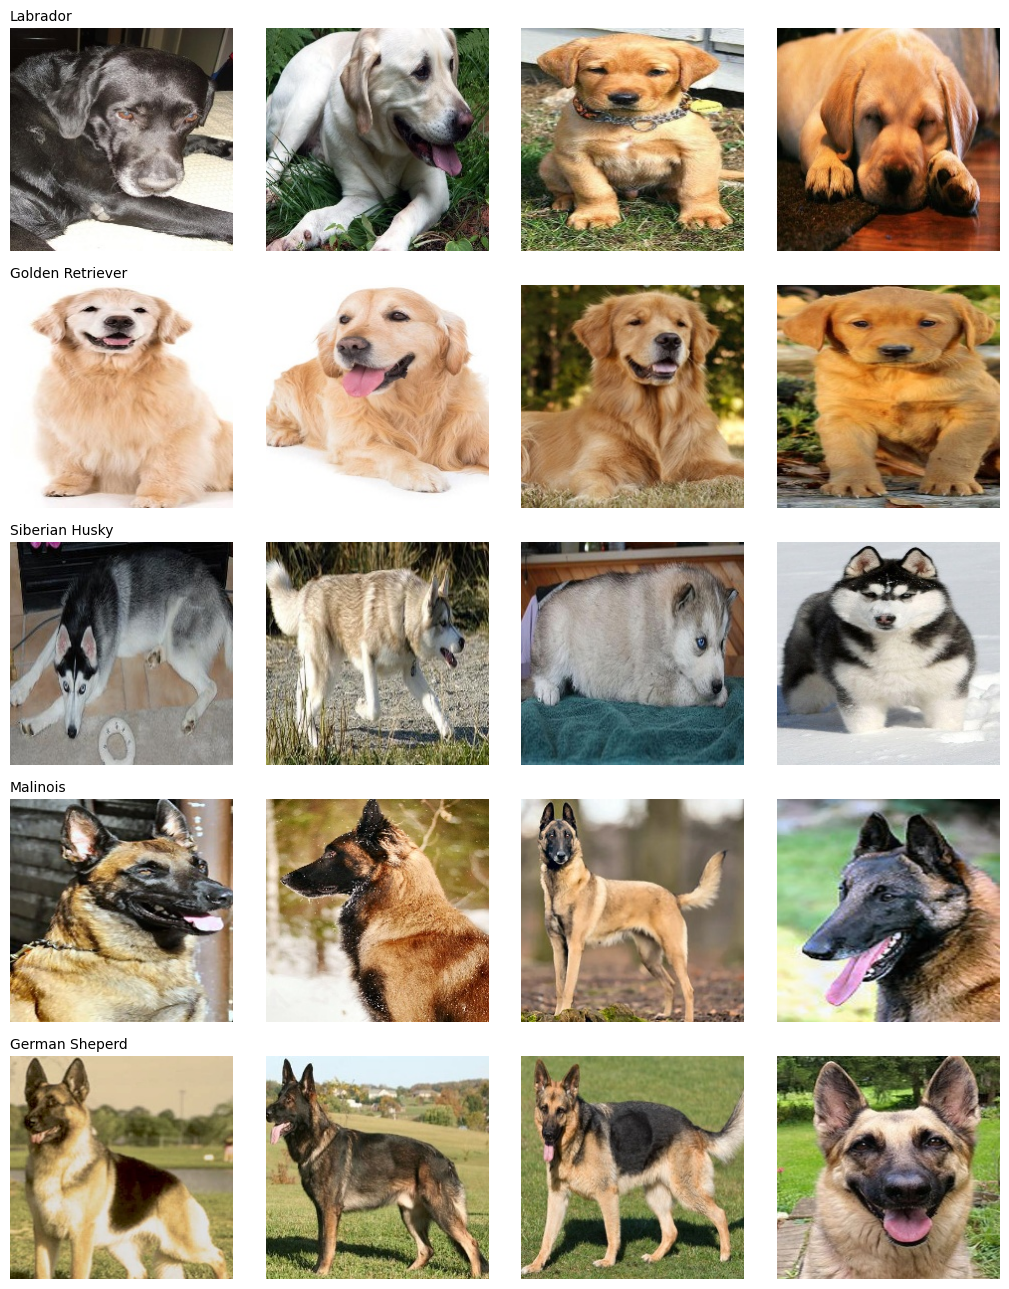

In [6]:
def grilla(razas, n=4):
    fig, ejes = plt.subplots(len(razas), n, figsize=(2.6 * n, 2.6 * len(razas)))
    for i, raza in enumerate(razas):
        rutas = df[(df["breed"] == raza) & (df["split"] == "train")]["path"].head(n)
        for j, ruta in enumerate(rutas):
            ejes[i, j].imshow(Image.open(root / ruta))
            ejes[i, j].axis("off")
        ejes[i, 0].set_title(raza, loc="left", fontsize=10)
    plt.tight_layout()
    plt.show()

grilla(["Labrador", "Golden Retriever", "Siberian Husky", "Malinois", "German Sheperd"])

### Distribución de clases
Los conteos por raza y por split y el gráfico de barras están en la sección 5. En resumen: `valid` y `test` tienen exactamente 10 imágenes por raza; `train` tiene entre 65 y 198 (mediana 111,5), es decir, un desbalance moderado (la raza más grande tiene unas 3 veces las imágenes de la más chica). Esto lo tenemos en cuenta al entrenar (pesos por clase o muestreo ponderado). Con solo 10 imágenes por raza en `valid` y `test`, las métricas por raza son inestables, y las globales (700 imágenes) son más confiables.


Archivos del CSV que existen: True
Razas: 70
split  test       train  valid
mean   10.0  113.514286   10.0
50%    10.0  111.500000   10.0
min    10.0   65.000000   10.0
max    10.0  198.000000   10.0


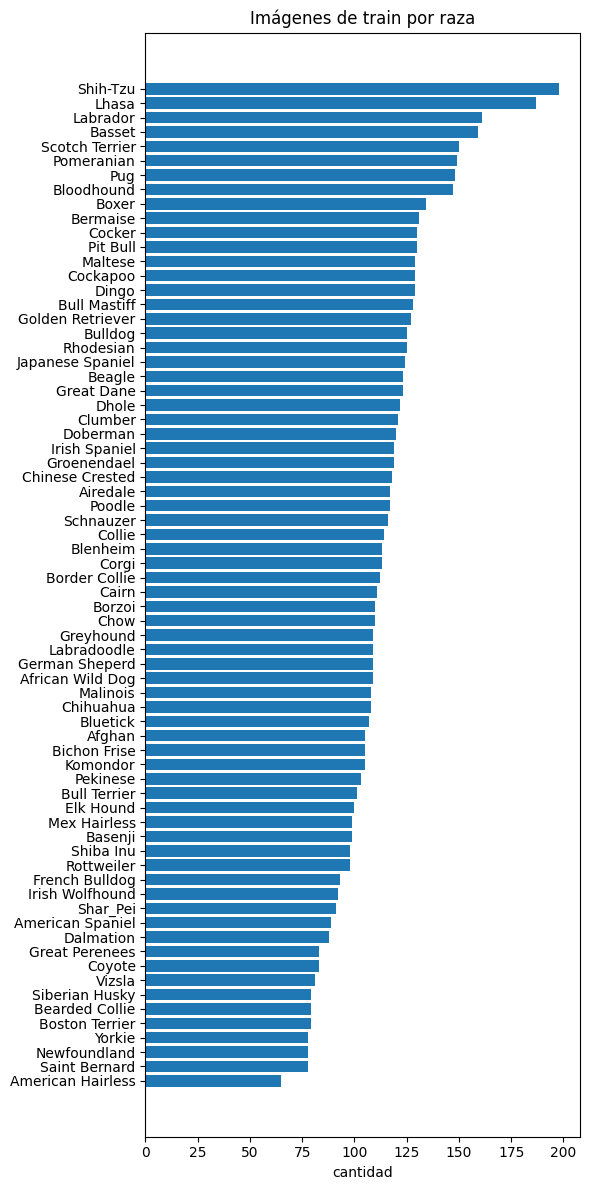

In [7]:
root = Path("data/dataset")
df = pd.read_csv(root / "dogs.csv").rename(
    columns={"filepaths": "path", "labels": "breed", "data set": "split"}
)
# Corrige etiqueta con espacios duplicados (ver sección 7)
df["breed"] = df["breed"].str.split().str.join(" ")

print("Archivos del CSV que existen:", df["path"].map(lambda p: (root / p).exists()).all())
print("Razas:", df["breed"].nunique())

conteo = df.groupby(["breed", "split"]).size().unstack("split").fillna(0).astype(int)
print(conteo.describe().loc[["mean", "50%", "min", "max"]])

train = conteo["train"].sort_values()
plt.figure(figsize=(6, 12))
plt.barh(train.index, train.values)
plt.title("Imágenes de train por raza")
plt.xlabel("cantidad")
plt.tight_layout()
plt.show()

### Resoluciones, canales y formato
Las 9.346 imágenes son JPEG, RGB, de 224 × 224 (relación de aspecto 1,0 en todas) y ninguna está corrupta. Como todas tienen el mismo tamaño, no hace falta reescalar el dataset; el preprocesamiento sí tiene que contemplar recortes de YOLO con otras proporciones (sección 9).



In [8]:
filas, corruptas = [], []
for p in df["path"]:
    try:
        with Image.open(root / p) as im:
            im.verify()
        with Image.open(root / p) as im:
            filas.append((p, im.size[0], im.size[1], im.mode, im.format))
    except Exception:
        corruptas.append(p)

sizes = pd.DataFrame(filas, columns=["path", "ancho", "alto", "modo", "formato"])
sizes["aspecto"] = sizes["ancho"] / sizes["alto"]
print(sizes[["ancho", "alto", "aspecto"]].describe())
print(sizes["modo"].value_counts())
print(sizes["formato"].value_counts())
print("Archivos corruptos:", len(corruptas))

        ancho    alto  aspecto
count  9346.0  9346.0   9346.0
mean    224.0   224.0      1.0
std       0.0     0.0      0.0
min     224.0   224.0      1.0
25%     224.0   224.0      1.0
50%     224.0   224.0      1.0
75%     224.0   224.0      1.0
max     224.0   224.0      1.0
modo
RGB    9346
Name: count, dtype: int64
formato
JPEG    9346
Name: count, dtype: int64
Archivos corruptos: 0


### Variaciones
Hay variación de pose (echado, de pie, de perfil), fondo (pasto, nieve, interior, estudio blanco), edad (cachorros y adultos) y color dentro de una misma raza. En la muestra visual cada imagen tiene un solo perro, centrado y en primer plano, sin personas ni objetos relevantes.

La iluminación varía bastante: en una muestra de 1.000 imágenes, el brillo medio tiene mediana 123 (rango de 37 a 233) y el contraste tiene mediana 58 (rango de 22 a 109). Hay imágenes muy oscuras, muy claras y de bajo contraste, por eso incluimos variaciones de brillo y contraste en la data augmentation (sección 10).

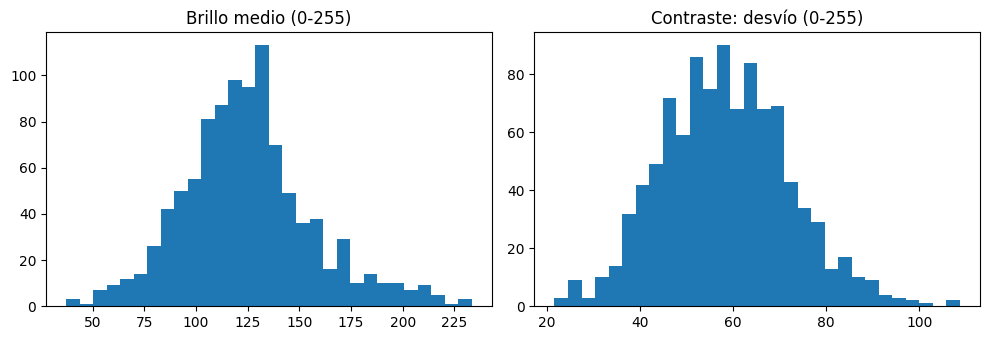

Brillo:    mín 37 | mediana 123 | máx 233
Contraste: mín 22 | mediana 58 | máx 109


In [9]:
muestra = df.sample(1000, random_state=42)   # muestra fija para que sea reproducible
brillo, contraste = [], []
for ruta in muestra["path"]:
    gris = np.asarray(Image.open(root / ruta).convert("L"), dtype=np.float32)
    brillo.append(gris.mean())
    contraste.append(gris.std())

fig, ejes = plt.subplots(1, 2, figsize=(10, 3.5))
ejes[0].hist(brillo, bins=30);    ejes[0].set_title("Brillo medio (0-255)")
ejes[1].hist(contraste, bins=30); ejes[1].set_title("Contraste: desvío (0-255)")
plt.tight_layout(); plt.show()

print(f"Brillo:    mín {min(brillo):.0f} | mediana {np.median(brillo):.0f} | máx {max(brillo):.0f}")
print(f"Contraste: mín {min(contraste):.0f} | mediana {np.median(contraste):.0f} | máx {max(contraste):.0f}")

## 7. Control de calidad y filtrado

Definimos reglas explícitas y reproducibles. Para cada una se informa cuántas imágenes detecta y se muestran ejemplos. Se miden sobre los tres splits, pero se **protege la evaluación**: en `test` y `valid` solo se descartan imágenes con etiqueta ambigua y las copias de `valid` que están también en `test`; las borrosas se descartan solo de `train`.


### Resultado
Se descartan **477 imágenes (5,1%)**. Quedan **8.869**: train 7.487, valid 684, test 698. Con esto `valid` y `test` ya no tienen exactamente 10 imágenes por raza (se verifica en la sección 11).

### Regla 1: etiquetas inconsistentes
El CSV del dataset tenía una raza escrita de dos formas: las 10 imágenes de `valid` figuraban como "American  Spaniel" (con dos espacios) y las de `train` y `test` como "American Spaniel". Para el código eran dos razas distintas: 71 clases, una sin imágenes de entrenamiento y otra sin imágenes de validación. Se corrige colapsando los espacios repetidos de todas las etiquetas (quedan 70 razas, con 10 imágenes por raza en `valid` y `test`). Las rutas de los archivos no se modifican.


In [10]:
crudo = pd.read_csv(root / "dogs.csv").rename(
    columns={"filepaths": "path", "labels": "breed", "data set": "split"}
)
print("Razas en el CSV original:", crudo["breed"].nunique(), "| después de corregir:", df["breed"].nunique())
print(crudo[crudo["breed"].str.contains("American Spaniel|American  Spaniel")].groupby(["breed", "split"]).size())

Razas en el CSV original: 71 | después de corregir: 70
breed              split
American  Spaniel  valid    10
American Spaniel   test     10
                   train    89
dtype: int64




### Regla 2: imágenes borrosas
Se mide la nitidez con la varianza del Laplaciano. Como es muy asimétrica, el umbral se calcula con el criterio IQR sobre su logaritmo (Q1 − 1,5 × IQR), que equivale a 74,1. Los ejemplos más borrosos lo son, pero la regla también marca algunas fotos nítidas de perros con pelaje blanco o liso (menos bordes) y se concentra levemente en razas de pelo largo y claro (Pomeranian, Maltese, Pekinese: ≤ 4% de cada una). Se descartan solo las de `train` (menos del 1%).

Umbral de nitidez (varianza Laplaciano): 74.1
       borrosa  mal_expuesta
split                       
test         6             1
train       46            16
valid        7             0


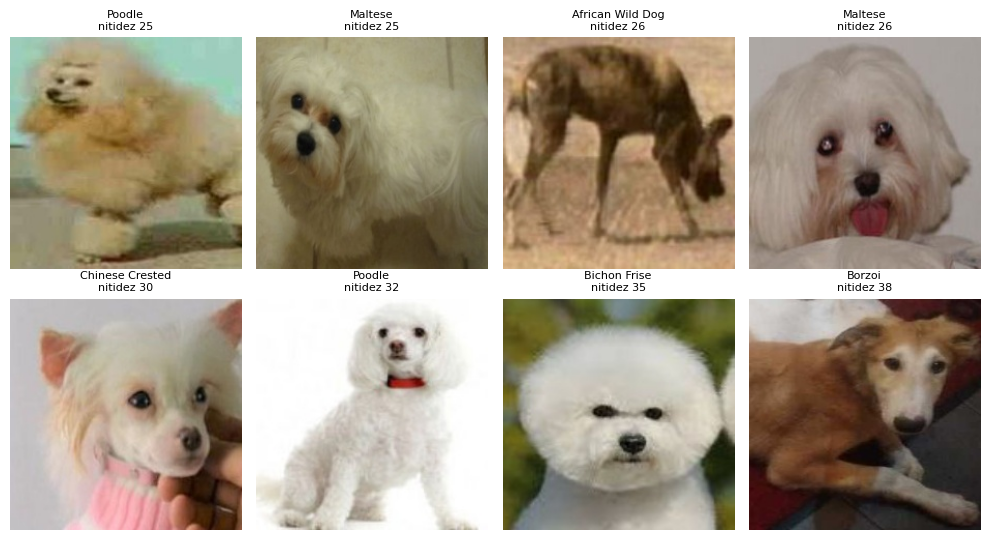

In [11]:
medidas = []
for ruta in df["path"]:
    gris = cv2.imread(str(root / ruta), cv2.IMREAD_GRAYSCALE)
    medidas.append((cv2.Laplacian(gris, cv2.CV_64F).var(), float(gris.mean())))
df[["nitidez", "brillo"]] = pd.DataFrame(medidas, index=df.index)

# Regla 2: borrosas. IQR sobre log(nitidez): umbral = Q1 - 1.5 * IQR
log_nit = np.log1p(df["nitidez"])
q1, q3 = log_nit.quantile([0.25, 0.75])
umbral_log = q1 - 1.5 * (q3 - q1)
df["borrosa"] = log_nit < umbral_log

# Regla 3: exposición extrema (muy oscura o muy clara), umbrales fijos
df["mal_expuesta"] = (df["brillo"] < 25) | (df["brillo"] > 230)

print("Umbral de nitidez (varianza Laplaciano):", round(float(np.expm1(umbral_log)), 1))
print(df.groupby("split")[["borrosa", "mal_expuesta"]].sum())

# Ejemplos de descartadas por borrosas (las más borrosas primero)
peores = df[df["borrosa"]].sort_values("nitidez").head(8)
fig, ejes = plt.subplots(2, 4, figsize=(10, 5.5))
for eje, (_, fila) in zip(ejes.ravel(), peores.iterrows()):
    eje.imshow(Image.open(root / fila["path"]))
    eje.set_title(f"{fila['breed']}\nnitidez {fila['nitidez']:.0f}", fontsize=8)
    eje.axis("off")
plt.tight_layout(); plt.show()

In [12]:
marcadas = df[df["borrosa"]].groupby("breed").size().sort_values(ascending=False)
totales = df.groupby("breed").size()
tabla = pd.DataFrame({"borrosas": marcadas, "total": totales}).dropna()
tabla["%"] = (100 * tabla["borrosas"] / tabla["total"]).round(1)
print(tabla.sort_values("borrosas", ascending=False).head(10))

              borrosas  total    %
breed                             
Pomeranian         7.0    169  4.1
Maltese            6.0    149  4.0
Pekinese           5.0    123  4.1
Pit Bull           3.0    150  2.0
Vizsla             3.0    101  3.0
Bichon Frise       2.0    125  1.6
Groenendael        2.0    139  1.4
Mex Hairless       2.0    119  1.7
Shiba Inu          2.0    118  1.7
Beagle             2.0    143  1.4


### Regla 3: exposición extrema
Se probó marcar brillo medio < 25 o > 230: 17 imágenes. La inspección visual mostró que todas eran fotos de estudio con fondo blanco y el perro bien expuesto; el brillo alto viene del fondo. Un umbral de brillo medio no distingue ambos casos, así que **no se descarta ninguna imagen** por esta regla.




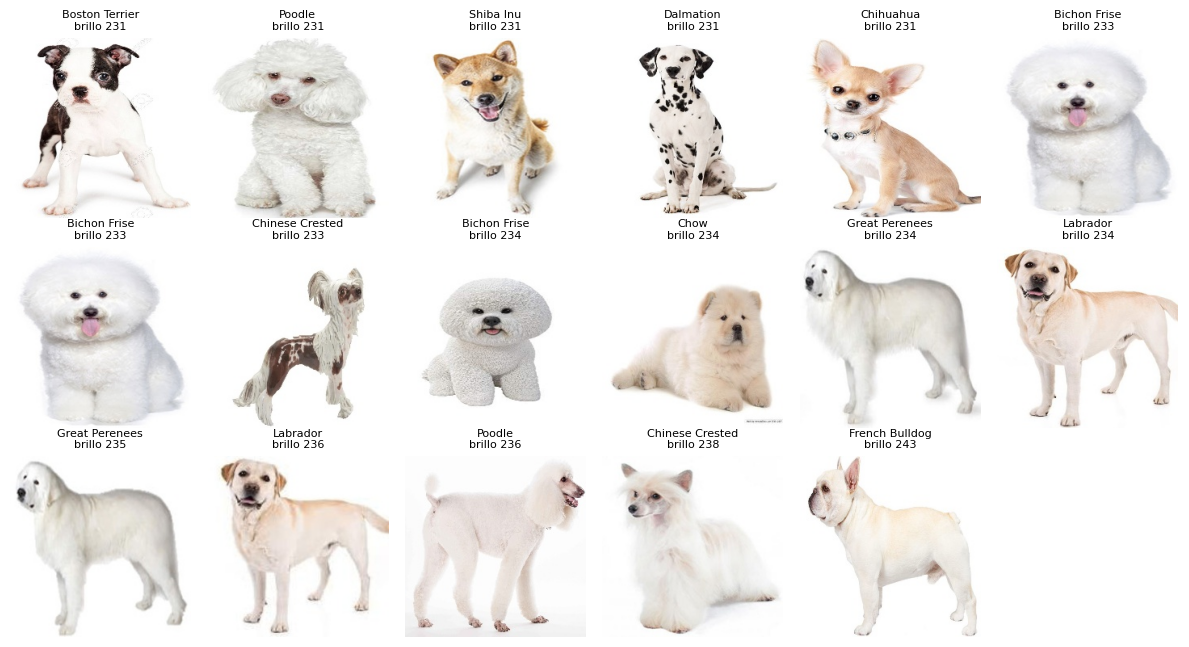

In [13]:
mal = df[df["mal_expuesta"]].sort_values("brillo")
fig, ejes = plt.subplots(3, 6, figsize=(12, 6.5))
for eje in ejes.ravel():
    eje.axis("off")
for eje, (_, fila) in zip(ejes.ravel(), mal.iterrows()):
    eje.imshow(Image.open(root / fila["path"]))
    eje.set_title(f"{fila['breed']}\nbrillo {fila['brillo']:.0f}", fontsize=8)
plt.tight_layout(); plt.show()

In [ ]:
# Regla 4: exposición extrema (brillo medio muy bajo o muy alto)
df["mal_expuesta"] = (df["brillo"] < 25) | (df["brillo"] > 230)
print(df.groupby("split")["mal_expuesta"].sum())

split
test      1
train    16
valid     0
Name: mal_expuesta, dtype: int64


### Regla 4: duplicados y fuga de datos
Se calcula un hash perceptual (pHash de 64 bits) de cada imagen y se compara la distancia de Hamming entre todos los pares. Se probaron umbrales entre 2 y 16. Hasta 8, ≥ 97% de los pares detectados son de la misma raza (el azar daría ~1,4%) y la inspección visual confirmó que son la misma foto con pequeñas variaciones de brillo, recorte o compresión. Desde 10, ese porcentaje cae (88%, 55%, 22%), lo que indica que se mezclan perros distintos. Se adopta **Hamming ≤ 8**, que detecta 177 pares entre splits (con el umbral 2 hubieran sido 105).
Criterio de descarte: entre splits se borra la copia del split menos protegido (prioridad `test` > `valid` > `train`); dentro de `train` se conserva una sola copia. Los duplicados dentro de `valid` (10 pares) y de `test` (7 pares) no se borran, para no perder imágenes de evaluación; es una limitación menor.

In [14]:
# 1) Huella (pHash de 64 bits) de cada imagen
hashes = []
for ruta in df["path"]:
    with Image.open(root / ruta) as im:
        hashes.append(imagehash.phash(im).hash.flatten())
H = np.array(hashes, dtype=np.float32)          # (n_imágenes, 64)

# 2) Distancia de Hamming entre todos los pares, por bloques para no usar mucha memoria
UMBRAL_HAMMING = 8
pares = []
for i in range(0, len(H), 1000):
    bloque = H[i:i + 1000]
    dist = H.shape[1] - (bloque @ H.T + (1 - bloque) @ (1 - H).T)
    for f, c in zip(*np.where(dist <= UMBRAL_HAMMING)):
        a = f + i
        if a < c:                                # cada par una sola vez, sin compararla consigo misma
            pares.append((a, c, int(round(dist[f, c]))))

dup = pd.DataFrame(pares, columns=["i", "j", "hamming"])
for lado, col in (("a", "i"), ("b", "j")):
    dup[f"path_{lado}"] = df["path"].values[dup[col]]
    dup[f"split_{lado}"] = df["split"].values[dup[col]]
    dup[f"breed_{lado}"] = df["breed"].values[dup[col]]
dup["misma_raza"] = dup["breed_a"] == dup["breed_b"]

print("Pares con distancia de Hamming <=", UMBRAL_HAMMING, ":", len(dup))
print(dup.groupby(["split_a", "split_b"]).size())
print("¿Misma raza?:", dup["misma_raza"].value_counts().to_dict())

Pares con distancia de Hamming <= 8 : 498
split_a  split_b
test     test         7
         valid       14
train    test        80
         train      304
         valid       83
valid    valid       10
dtype: int64
¿Misma raza?: {True: 483, False: 15}


In [15]:
prioridad = {"test": 0, "valid": 1, "train": 2}   # menor número = más protegido

# Duplicados: entre splits se borra la copia del split menos protegido;
# dentro de train se queda una sola copia.
a_borrar = set()
for _, p in dup.iterrows():
    sa, sb = p["split_a"], p["split_b"]
    if sa == sb:
        if sa == "train":
            a_borrar.add(p["j"])
    else:
        a_borrar.add(p["i"] if prioridad[sa] > prioridad[sb] else p["j"])
df["duplicada"] = df.index.isin(a_borrar)

# Etiqueta ambigua: la misma foto con dos razas distintas -> se descartan las dos
conflicto = set(dup.loc[~dup["misma_raza"], "i"]) | set(dup.loc[~dup["misma_raza"], "j"])
df["etiqueta_ambigua"] = df.index.isin(conflicto)

# Cada imagen se cuenta en una sola regla (en este orden)
d1 = df["etiqueta_ambigua"]
d2 = df["duplicada"] & ~d1
d3 = (df["borrosa"] & (df["split"] == "train")) & ~d1 & ~d2
df["descartar"] = d1 | d2 | d3

cuadro = pd.DataFrame({
    "etiqueta ambigua": d1.groupby(df["split"]).sum(),
    "duplicadas": d2.groupby(df["split"]).sum(),
    "borrosas (solo train)": d3.groupby(df["split"]).sum(),
})
cuadro["total descartadas"] = cuadro.sum(axis=1)
cuadro["antes"] = df.groupby("split").size()
cuadro["quedan"] = cuadro["antes"] - cuadro["total descartadas"]
print(cuadro)
print("\nTotal:", cuadro[["total descartadas", "antes", "quedan"]].sum().to_dict())

       etiqueta ambigua  duplicadas  borrosas (solo train)  total descartadas  \
split                                                                           
test                  2           0                      0                  2   
train                21         394                     44                459   
valid                 2          14                      0                 16   

       antes  quedan  
split                 
test     700     698  
train   7946    7487  
valid    700     684  

Total: {'total descartadas': 477, 'antes': 9346, 'quedan': 8869}


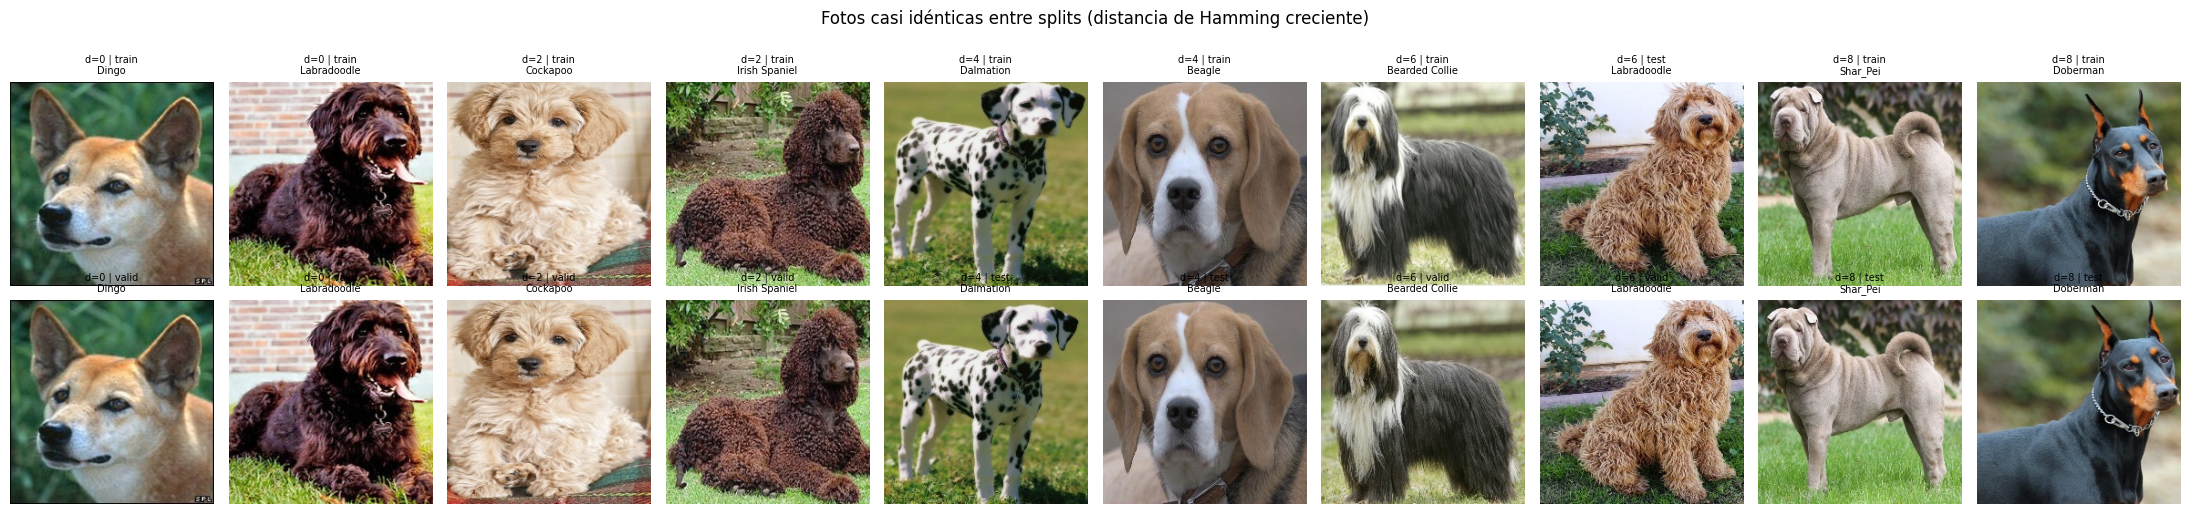

In [16]:
cruz = dup[dup["split_a"] != dup["split_b"]]
muestra = pd.concat(
    [g.sample(min(len(g), 2), random_state=0) for _, g in cruz.groupby("hamming")]
).sort_values("hamming")

n = len(muestra)
fig, ejes = plt.subplots(2, n, figsize=(2.2 * n, 5), squeeze=False)
for k, (_, p) in enumerate(muestra.iterrows()):
    for fila, lado in enumerate("ab"):
        ejes[fila, k].imshow(Image.open(root / p[f"path_{lado}"]))
        ejes[fila, k].axis("off")
        ejes[fila, k].set_title(f"d={p['hamming']} | {p[f'split_{lado}']}\n{p[f'breed_{lado}']}", fontsize=7)
plt.suptitle("Fotos casi idénticas entre splits (distancia de Hamming creciente)", y=1.02)
plt.tight_layout(); plt.show()

### Resumen de descartes

| Regla | Qué detecta | train | valid | test | Total |
|---|---|---|---|---|---|
| 1. Etiquetas inconsistentes | Una raza escrita de dos formas (71 → 70 razas) | 0 | 0 | 0 | **0** (se corrige) |
| 2. Imágenes borrosas | Marca 46 / 7 / 6; se descartan solo las de `train` | 44 | 0 | 0 | **44** |
| 3. Exposición extrema | Marca 16 / 0 / 1; falsos positivos (fondo blanco) | 0 | 0 | 0 | **0** (no se aplica) |
| 4. Duplicados y fuga de datos | Copias entre splits y dentro de `train` (Hamming ≤ 8) | 394 | 14 | 0 | **408** |
| 4. Etiqueta ambigua | La misma foto con dos razas distintas | 21 | 2 | 2 | **25** |
| **Total descartadas** | | **459** | **16** | **2** | **477** |

Cada imagen se cuenta una sola vez. Se descarta el **5,1%** del dataset (477 de 9.346).

| Split | Antes | Después |
|---|---|---|
| train | 7.946 | 7.487 |
| valid | 700 | 684 |
| test | 700 | 698 |
| **Total** | **9.346** | **8.869** |

## 8. Conjunto independiente de evaluación

Imágenes que **no pertenecen al dataset**, descargadas de Wikimedia Commons
(o fotos propias), para medir el comportamiento del sistema "en el mundo real".

- **Un perro por imagen** (20 razas, carpetas con el nombre exacto del dataset): Etapas 1 y 2.
- **`varios_perros/`**: escenas con 2 o más perros, para la Etapa 3.
- **`sin_perros/`**: gatos, zorros, peluches y escenas vacías, para medir falsos positivos del detector.

Incluye razas fáciles de confundir: Labrador / Golden Retriever, Malinois / German Sheperd,
Bulldog / French Bulldog, Maltese / Bichon Frise / Pomeranian.

Se guardan en `data/dataset/independent/` (excluido por `.gitignore`) y se comparten por Drive: falta que completemos.
La fuente y la licencia de cada imagen están en `fuentes.csv` (falta hacerlo).

In [17]:
print(sorted(p.name for p in (root / "train").iterdir() if p.is_dir()))

['Afghan', 'African Wild Dog', 'Airedale', 'American Hairless', 'American Spaniel', 'Basenji', 'Basset', 'Beagle', 'Bearded Collie', 'Bermaise', 'Bichon Frise', 'Blenheim', 'Bloodhound', 'Bluetick', 'Border Collie', 'Borzoi', 'Boston Terrier', 'Boxer', 'Bull Mastiff', 'Bull Terrier', 'Bulldog', 'Cairn', 'Chihuahua', 'Chinese Crested', 'Chow', 'Clumber', 'Cockapoo', 'Cocker', 'Collie', 'Corgi', 'Coyote', 'Dalmation', 'Dhole', 'Dingo', 'Doberman', 'Elk Hound', 'French Bulldog', 'German Sheperd', 'Golden Retriever', 'Great Dane', 'Great Perenees', 'Greyhound', 'Groenendael', 'Irish Spaniel', 'Irish Wolfhound', 'Japanese Spaniel', 'Komondor', 'Labradoodle', 'Labrador', 'Lhasa', 'Malinois', 'Maltese', 'Mex Hairless', 'Newfoundland', 'Pekinese', 'Pit Bull', 'Pomeranian', 'Poodle', 'Pug', 'Rhodesian', 'Rottweiler', 'Saint Bernard', 'Schnauzer', 'Scotch Terrier', 'Shar_Pei', 'Shiba Inu', 'Shih-Tzu', 'Siberian Husky', 'Vizsla', 'Yorkie']


In [19]:
from google.colab import drive
drive.mount("/content/drive")
!cp -r "/content/drive/MyDrive/dt_razas/independent" data/dataset/
!ls data/dataset/independent

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
'Bichon Frise'	  Dalmation	      Labrador	  'Shiba Inu'
'Border Collie'   Doberman	      Malinois	  'Siberian Husky'
 Boxer		 'French Bulldog'     Maltese	   sin_perros
 Bulldog	 'German Sheperd'     Pomeranian   varios_perros
 Chihuahua	 'Golden Retriever'   Pug
 Corgi		 'Great Dane'	      Rottweiler


In [20]:
indep_root = root / "independent"
razas_dataset = set(df["breed"])
extras = {"varios_perros", "sin_perros"}

filas = []
for carpeta in sorted(p for p in indep_root.iterdir() if p.is_dir()):
    for img in carpeta.glob("*"):
        if img.suffix.lower() in {".jpg", ".jpeg", ".png", ".webp"}:
            filas.append((str(img), carpeta.name))
indep = pd.DataFrame(filas, columns=["path", "breed"])

print("Carpetas que no coinciden con ninguna raza:", (set(indep["breed"]) - razas_dataset - extras) or "ninguna")
print("Razas cubiertas:", indep["breed"].isin(razas_dataset).groupby(indep["breed"]).any().sum())
print("Imágenes totales:", len(indep))
print(indep["breed"].value_counts())

Carpetas que no coinciden con ninguna raza: ninguna
Razas cubiertas: 20
Imágenes totales: 110
breed
Bichon Frise        5
Border Collie       5
Boxer               5
Bulldog             5
Chihuahua           5
Corgi               5
Dalmation           5
Doberman            5
French Bulldog      5
German Sheperd      5
Golden Retriever    5
Great Dane          5
Labrador            5
Malinois            5
Maltese             5
Pomeranian          5
Pug                 5
Rottweiler          5
Shiba Inu           5
Siberian Husky      5
sin_perros          5
varios_perros       5
Name: count, dtype: int64


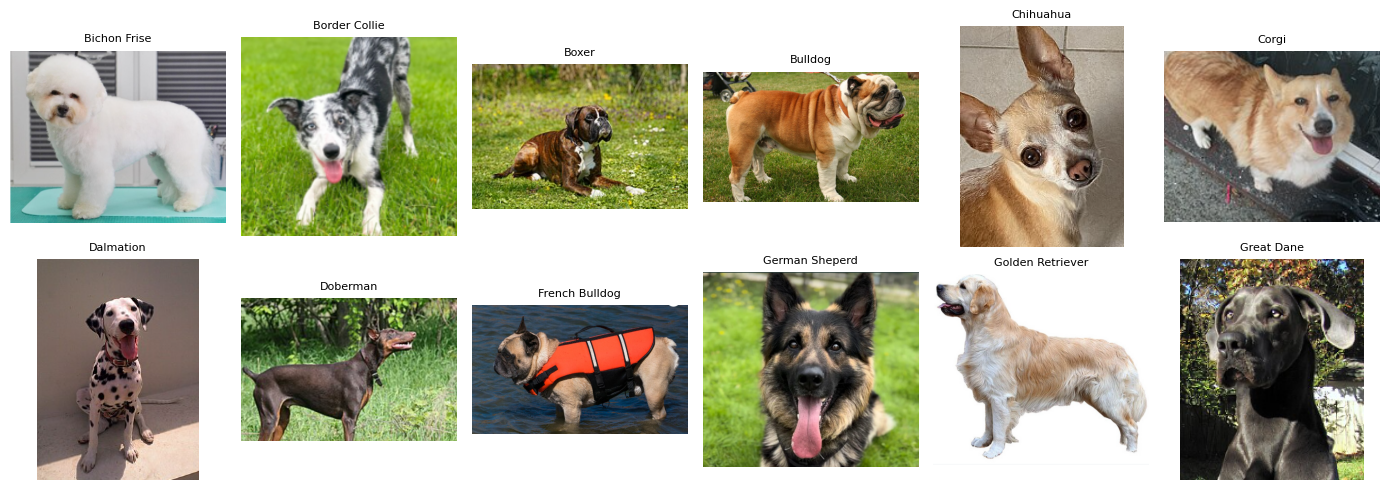

In [21]:
muestra = indep.groupby("breed").head(1).head(12)
fig, ejes = plt.subplots(2, 6, figsize=(14, 5))
for eje in ejes.ravel():
    eje.axis("off")
for eje, (_, f) in zip(ejes.ravel(), muestra.iterrows()):
    eje.imshow(Image.open(f["path"]).convert("RGB"))
    eje.set_title(f["breed"], fontsize=8)
plt.tight_layout(); plt.show()

A diferencia del dataset (todas cuadradas de 224 × 224), las imágenes del conjunto independiente
tienen resoluciones y relaciones de aspecto variadas, fondos distintos (estudio blanco, exteriores,
interiores) y algunos accesorios (chaleco, collar). Esto lo acerca más a los recortes que recibirá
el clasificador en la Etapa 3 y permite medir el cambio de dominio.

In [24]:
tam = indep["path"].map(lambda p: Image.open(p).size)
indep["ancho"], indep["alto"] = tam.str[0], tam.str[1]
indep["aspecto"] = indep["ancho"] / indep["alto"]
print(indep[["ancho", "alto", "aspecto"]].describe().round(2))

         ancho    alto  aspecto
count   110.00  110.00   110.00
mean    406.55  334.08     1.25
std     207.24  160.04     0.35
min     118.00  162.00     0.55
25%     275.75  210.00     0.97
50%     336.50  237.50     1.32
75%     530.75  433.25     1.49
max    1211.00  833.00     2.09


**Resoluciones del conjunto independiente:** ancho entre 118 y 1211 px (mediana 336), alto entre
162 y 833 px (mediana 238) y relación de aspecto entre 0,55 y 2,09 (mediana 1,32). En el dataset
todas las imágenes son de 224 × 224 (aspecto 1,0). Hay imágenes más chicas que 224 px, que al
reescalarse pierden nitidez, igual que los recortes chicos de YOLO. Por la variedad de aspectos,
un resize directo a 224 × 224 deformaría al perro; esto se tiene en cuenta en el preprocesamiento
(sección 9).

In [22]:
h_indep = np.array([imagehash.phash(Image.open(p).convert("RGB")).hash.flatten()
                    for p in indep["path"]], dtype=np.float32)
dist = H.shape[1] - (h_indep @ H.T + (1 - h_indep) @ (1 - H).T)
indep["hamming_min"] = dist.min(axis=1)
print("Posibles duplicados con el dataset:", (indep["hamming_min"] <= UMBRAL_HAMMING).sum())
print(indep[indep["hamming_min"] <= UMBRAL_HAMMING])

Posibles duplicados con el dataset: 0
Empty DataFrame
Columns: [path, breed, hamming_min]
Index: []


Ninguna imagen del conjunto independiente está a distancia de Hamming ≤ 8 de alguna imagen del
dataset (mismo pHash y umbral que en la sección 7), por lo que no hay fuga de datos entre el
conjunto independiente y train / valid / test.

**Casos para la Etapa 3:** varios perros y sin perros

Escenas con 2 o más perros (algunos superpuestos) para evaluar la detección múltiple, e imágenes
sin perros (gatos, perros de jueguete, objetos, escenas vacías) para medir falsos positivos del detector.

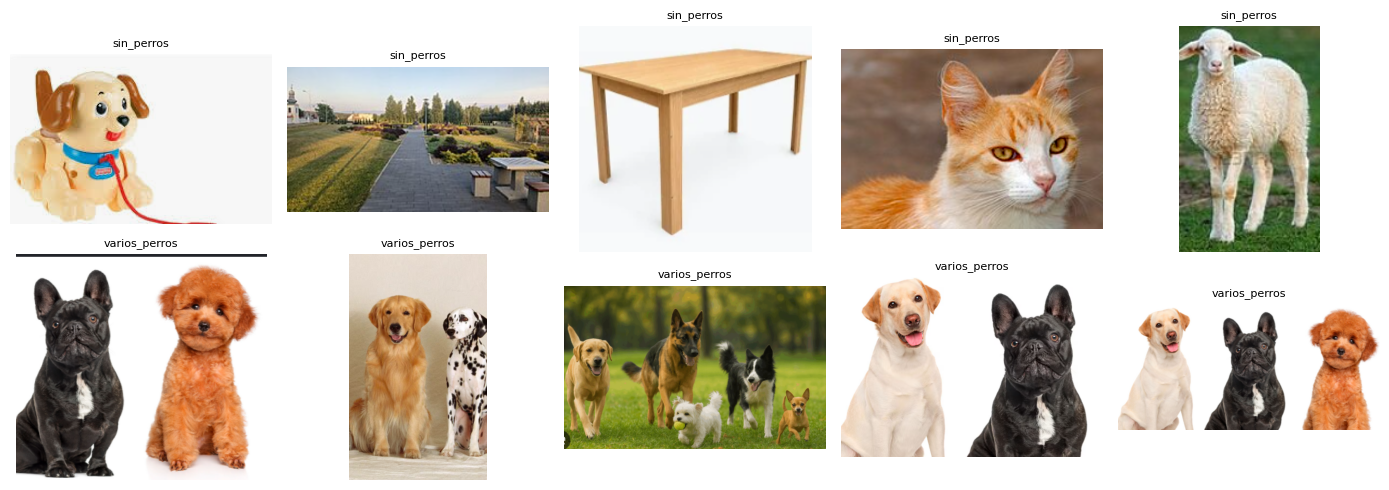

In [25]:
extra = indep[indep["breed"].isin(["varios_perros", "sin_perros"])]
fig, ejes = plt.subplots(2, 5, figsize=(14, 5))
for eje, (_, f) in zip(ejes.ravel(), extra.iterrows()):
    eje.imshow(Image.open(f["path"]).convert("RGB")); eje.set_title(f["breed"], fontsize=8); eje.axis("off")
plt.tight_layout(); plt.show()

## 9. Preprocesamiento

TO-DO: definir y justificar el resize, la normalización y el orden de canales (la app entrega BGR).

⚠️ El mismo preprocesamiento debe usarse en las notebooks y en los servicios de la app:
encapsulalo en un módulo de `src/lib/` e importalo desde ambos lados.

In [ ]:
## TO-DO: transformaciones de preprocesamiento (importadas desde el módulo compartido).

## 10. Data augmentation

TO-DO: horizontal flip, rotación, blur, variaciones de brillo y contraste y ruido, con sus rangos
justificados. Mostrar una grilla de ejemplos aumentados de una misma imagen. Solo sobre `train`.

In [ ]:
## TO-DO: pipeline de data augmentation con ejemplos visuales.

## 11. Splits

TO-DO: definir train / validation / test (los del dataset o redefinidos, justificando), verificar
que no haya fuga de datos entre splits, fijar semillas y guardar los splits finales (CSV/JSON con
rutas y etiquetas) para `2-train.ipynb`.

In [ ]:
## TO-DO: splits finales, verificación de fuga de datos y exportación.

## 12. Resumen final

TO-DO: tabla con la cantidad de razas e imágenes por split, incluido el conjunto independiente.

In [ ]:
## TO-DO: tabla resumen.

## 13. Licencias y uso de imágenes

TO-DO: licencia del dataset, fuente y licencia de las imágenes del conjunto independiente y criterio
aplicado a imágenes con personas identificables.